In [1]:
import lightning as L
import torch
import math
from torch.utils.data import DataLoader

from data import (
    Division,
    RegressionDataset,
    Multiplication,
    EML,
    Matyas,
    Exp,
    Runge,
    NestedRational,
    BilinearRatio,
    RationalInteraction,
    Add,
    Subtraction,
)
from models import Network
from nn import SNS, Linear
from optim import ZoVanilla, ZoAR
from utils import plot_mlp, plot_sns


W0906 18:28:27.774000 32856 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


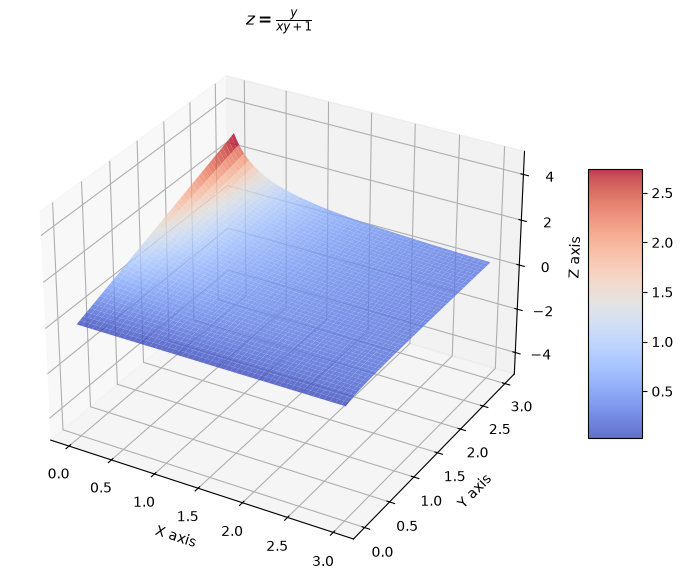

In [ ]:
# Create grid of x and y values
x = np.linspace(0, 3, 300)
y = np.linspace(0, 3, 300)
X, Y = np.meshgrid(x, y)

# Calculate Z, masking values near the asymptote xy = -1 to prevent spikes
Z = Y / (X * Y + 1)
Z[np.abs(X * Y + 1) < 0.05] = np.nan

# Setup 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot the surface
surf = ax.plot_surface(X, Y, Z, cmap="coolwarm", edgecolor="none", alpha=0.8)

# Labels and limits
ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")
ax.set_title(r"$z = \frac{y}{xy + 1}$")
ax.set_zlim(-5, 5)

fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

In [153]:
training_dataset.y_max

tensor([223.9124])

In [154]:
training_dataset.y_min

tensor([2.6528e-05])

In [2]:
training_dataset = RegressionDataset(
    RationalInteraction(), num_samples=10000, low=[0, 0, 0], high=[5, 5, 5], noise_level=0.0, normalize=False
)
validation_dataset = RegressionDataset(
    RationalInteraction(), num_samples=3000, low=[0, 0, 0], high=[5, 5, 5], noise_level=0.0, normalize=False
)

# training_dataset = RegressionDataset(NestedRational(), num_samples=10000, low = [0, 0, 0], high = [2.0, 2.0, 2.0], noise_level=0)

train_loader = DataLoader(training_dataset, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=32, shuffle=False)


Text(0.5, 0, 'Z Label')

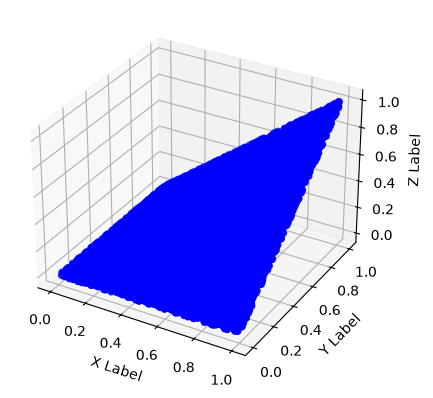

In [3]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

# Plot the 3D scatter data

ax.scatter(
    training_dataset.data["features"][:, 0],
    training_dataset.data["features"][:, 1],
    training_dataset.data["labels"][:, 0],
    c="blue",
    marker="o",
)

# ax.scatter(training_dataset.data["features"][:, 0], training_dataset.data["features"][:, 1], training_dataset.data["features"][:, 2], c=training_dataset.data["labels"][:,0], cmap='viridis', s=40, edgecolors='w', linewidth=0.5)

# Add axis labels
ax.set_xlabel("X Label")
ax.set_ylabel("Y Label")
ax.set_zlabel("Z Label")

# ax.view_init(elev=30, azim=45, roll=0)

In [27]:
training_dataset.data["features"][:100, 0]

tensor([0.4008, 0.8008, 0.9844, 0.7091, 0.2861, 0.9114, 0.1383, 0.5031, 0.6948,
        0.3165, 0.6642, 0.8140, 0.4932, 0.3416, 0.1181, 0.1992, 0.8046, 0.7680,
        0.6853, 0.1149, 0.7199, 0.6368, 0.4559, 0.2560, 0.8261, 0.2341, 0.6216,
        0.3617, 0.4860, 0.7584, 0.5927, 0.7829, 0.7520, 0.9993, 0.1330, 0.7965,
        0.3804, 0.6619, 0.4983, 0.0216, 0.8010, 0.6336, 0.6027, 0.9282, 0.1840,
        0.3656, 0.0234, 0.1957, 0.6288, 0.2513, 0.0593, 0.8496, 0.5386, 0.8429,
        0.1311, 0.1793, 0.4754, 0.3590, 0.1798, 0.0601, 0.2073, 0.0350, 0.6929,
        0.1206, 0.0048, 0.2461, 0.0277, 0.3233, 0.4707, 0.7609, 0.6939, 0.0743,
        0.1559, 0.7770, 0.4605, 0.9560, 0.8620, 0.4227, 0.5718, 0.4051, 0.6959,
        0.6473, 0.8603, 0.5639, 0.5732, 0.7466, 0.6698, 0.6797, 0.1198, 0.8070,
        0.6863, 0.8971, 0.7018, 0.5386, 0.3320, 0.6494, 0.8036, 0.6481, 0.0506,
        0.7712])

In [28]:
training_dataset.data["features"][:100, 1]

tensor([0.1425, 0.4564, 0.6196, 0.1989, 0.4384, 0.4219, 0.2102, 0.4109, 0.1291,
        0.5561, 0.2273, 0.3718, 0.9046, 0.6511, 0.8678, 0.7780, 0.2708, 0.6057,
        0.8556, 0.4340, 0.6393, 0.8211, 0.1319, 0.2735, 0.5508, 0.5673, 0.4936,
        0.5580, 0.0270, 0.3277, 0.9102, 0.6942, 0.7016, 0.2675, 0.3661, 0.2705,
        0.0656, 0.7201, 0.0623, 0.3640, 0.5233, 0.6863, 0.5593, 0.8586, 0.2180,
        0.9545, 0.0784, 0.4560, 0.5507, 0.8975, 0.2094, 0.8986, 0.7614, 0.2007,
        0.5181, 0.5579, 0.1739, 0.7883, 0.4751, 0.1480, 0.8464, 0.5388, 0.6222,
        0.2296, 1.0000, 0.2163, 0.0245, 0.5731, 0.1080, 0.5067, 0.5195, 0.1873,
        0.2405, 0.4646, 0.5802, 0.6337, 0.2452, 0.8437, 0.6630, 0.7504, 0.1356,
        0.6072, 0.8429, 0.7275, 0.5279, 0.6823, 0.8717, 0.0960, 0.4817, 0.6957,
        0.5783, 0.6168, 0.0818, 0.4116, 0.9803, 0.5819, 0.1351, 0.0011, 0.9451,
        0.4272])

In [29]:
training_dataset.data["labels"][:100, 0]

tensor([0.2595, 0.3461, 0.3665, 0.5126, 0.1531, 0.4919, 0.0723, 0.0927, 0.5685,
        0.2407, 0.4389, 0.4444, 0.4134, 0.3110, 0.7534, 0.5816, 0.5364, 0.1630,
        0.1712, 0.3206, 0.0809, 0.1852, 0.3256, 0.0176, 0.2767, 0.3349, 0.1286,
        0.1973, 0.4613, 0.4328, 0.3191, 0.0892, 0.0506, 0.7354, 0.2342, 0.5285,
        0.3164, 0.0585, 0.4381, 0.3441, 0.2790, 0.0530, 0.0437, 0.0700, 0.0342,
        0.5918, 0.0553, 0.2616, 0.0785, 0.6494, 0.1509, 0.0493, 0.2239, 0.6454,
        0.3889, 0.3805, 0.3030, 0.4314, 0.2967, 0.0884, 0.6422, 0.5062, 0.0711,
        0.1096, 1.0000, 0.0299, 0.0032, 0.2510, 0.3644, 0.2554, 0.1752, 0.1136,
        0.0850, 0.3140, 0.1203, 0.3239, 0.6198, 0.4230, 0.0916, 0.3470, 0.5630,
        0.0403, 0.0175, 0.1644, 0.0455, 0.0646, 0.2029, 0.5865, 0.3637, 0.1119,
        0.1086, 0.2817, 0.6230, 0.1276, 0.6515, 0.0678, 0.6718, 0.6501, 0.8989,
        0.3457])

In [9]:
training_dataset.data["labels"][:100, 0]

tensor([0.4681, 0.7132, 0.8388, 0.2226, 0.1596, 0.1435, 0.1078, 0.7027, 0.1305,
        0.0067, 0.3079, 0.1993, 0.0186, 0.0474, 0.0232, 0.0168, 0.1947, 0.4548,
        0.1171, 0.3404, 0.1546, 0.0352, 0.6395, 0.4059, 0.1976, 0.6103, 0.1923,
        0.3989, 0.0322, 0.4835, 0.4946, 0.2855, 0.7136, 0.5839, 0.5370, 0.4985,
        0.6414, 0.5702, 0.2374, 0.5764, 0.3675, 0.0014, 0.1365, 0.4267, 0.6454,
        0.1277, 0.0363, 0.0915, 0.1105, 0.4371, 0.2103, 0.3970, 0.0308, 0.1154,
        0.1491, 0.1865, 0.2504, 0.4513, 0.1362, 0.0729, 0.0146, 0.5459, 0.3621,
        0.3443, 0.7826, 0.1531, 0.0722, 0.0122, 0.0507, 0.3018, 0.3818, 0.0804,
        0.2910, 0.2330, 0.2380, 0.5238, 0.0253, 0.1585, 0.2910, 0.3667, 0.3233,
        0.8628, 0.5198, 0.1198, 0.0265, 0.0849, 0.1007, 0.0409, 0.1360, 0.3329,
        0.0178, 0.5818, 0.3485, 0.2173, 0.0149, 0.7997, 0.5009, 0.0148, 0.1627,
        0.2464])

Text(0.5, 0, 'Z Label')

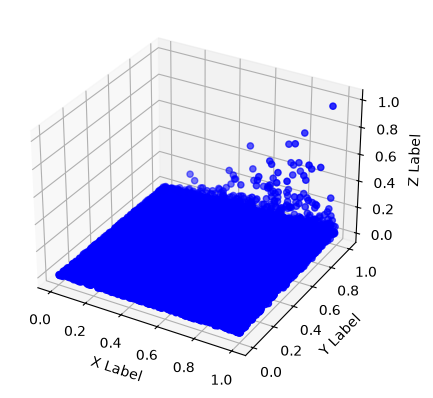

In [ ]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

# Plot the 3D scatter data
ax.scatter(
    training_dataset.data["features"][:, 1],
    training_dataset.data["features"][:, 0],
    training_dataset.data["labels"][:, 0],
    c="blue",
    marker="o",
)

# Add axis labels
ax.set_xlabel("X Label")
ax.set_ylabel("Y Label")
ax.set_zlabel("Z Label")

In [3]:
class ManualLitModel(L.LightningModule):
    def __init__(self, model, zo_optimizer):
        super().__init__()
        self.model = model
        self.zo_optimizer = zo_optimizer
        # Turn off automatic optimization
        self.automatic_optimization = False

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        # Pull your custom optimizer instance
        opt = self.optimizers()

        x, y = batch

        def closure():
            y_hat = self(x)
            loss = torch.nn.functional.mse_loss(y_hat, y)
            return loss

        # Trigger your optimizer's custom step
        loss = opt.step(closure)

        # print(f"Iteration {batch_idx:02d} | Objective Value: {loss:.4f}")

        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)

    def test_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("test_loss", loss)

    def configure_optimizers(self):
        return self.zo_optimizer(
            [p for p in self.parameters() if p.requires_grad], lr=1e-4
        )

In [4]:
class GModel0(L.LightningModule):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.train_loss = []

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model.forward(x)
        y_hat = y_hat.view_as(y)
        loss = torch.nn.functional.mse_loss(y_hat, y)
        # loss = nn.MSELoss()(y_hat.squeeze(dim=2)[:,-1], y.squeeze(dim=2)[:,-1])
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        # self.log("train_loss_epoch", loss, on_epoch=True, prog_bar=True)
        self.train_loss.append(loss)

        return loss

    def test_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("test_loss", loss)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-3)

In [84]:
from pytorch_lightning.callbacks import Callback

In [ ]:
class MetricsLogger(Callback):
    def __init__(self):
        super().__init__()
        self.train_losses = []

    def on_validation_epoch_end(self, trainer, pl_module):
        # Extract metrics from the trainer's logger after the validation epoch ends
        train_loss = trainer.callback_metrics.get("train_loss_epoch", None)

        # Only append metrics if they exist
        if train_loss is not None:
            self.train_losses.append(train_loss.item())

        # Optionally, print metrics for each epoch
        if train_loss is not None:
            print(f"Epoch {trainer.current_epoch}: train_loss={train_loss:.4f}")


In [8]:
layer_size = [3, 6, 4, 1]

In [5]:
layer_size = [3, 10, 10, 1]

In [5]:
model = Network(Linear, layer_size, skip_connection=False, ac=torch.nn.SiLU())
model_learning = ManualLitModel(model, ZoVanilla)

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(model_learning, train_dataloaders=train_loader)

NameError: name 'layer_size' is not defined

In [6]:
model = Network(Linear, layer_size, skip_connection=False, ac=torch.nn.SiLU())
model_learning = GModel0(model)


class LossHistoryCallback(L.Callback):
    def __init__(self):
        super().__init__()
        self.history = []

    def on_train_epoch_end(self, trainer, pl_module):
        # Retrieve the logged train_loss from callback_metrics
        train_loss = trainer.callback_metrics.get("train_loss")
        if train_loss is not None:
            self.history.append(train_loss.item())


# 1. Initialize your custom callback
history_cb = LossHistoryCallback()

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
    callbacks=[history_cb],
)

# Run the training execution pipeline
trainer.fit(model_learning, train_dataloaders=train_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
You are using a CUDA device ('NVIDIA GeForce RTX 4090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 322    | train | 0    
--------------------------------------------------
161       Trainable params
161       Non-trainable params
322       Total params
0.001     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
0         Total Flops
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 305.48it/s, v_num=382, train_loss_step=0.000134, train_loss_epoch=0.000204]

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 303.83it/s, v_num=382, train_loss_step=0.000134, train_loss_epoch=0.000204]


In [127]:
history_mlp = []

In [141]:
history_mlp.append(history_cb.history)

In [142]:
len(history_mlp)

5

In [131]:
history_cb.history

[0.021201860159635544,
 0.0020063668489456177,
 0.00166648393496871,
 0.0015242999652400613,
 0.001448427909053862,
 0.0014041822869330645,
 0.001375812105834484,
 0.0013515050522983074,
 0.001332577085122466,
 0.0013029130641371012,
 0.001277541508898139,
 0.0012409742921590805,
 0.0012021091533824801,
 0.0011621816083788872,
 0.0011183194583281875,
 0.001084091141819954,
 0.001046829274855554,
 0.0010180281242355704,
 0.0010044319787994027,
 0.0009926228085532784,
 0.0009819593979045749,
 0.0009797719540074468,
 0.0009807698661461473,
 0.0009701300878077745,
 0.0009726822609081864,
 0.0009681591182015836,
 0.0009657139889895916,
 0.0009681445080786943,
 0.0009724072297103703,
 0.0009663541568443179,
 0.0009638458141125739,
 0.0009632331784814596,
 0.0009624240919947624,
 0.0009612302528694272,
 0.0009627713006921113,
 0.0009602659265510738,
 0.0009648070554248989,
 0.000960990262683481,
 0.0009589547989889979,
 0.0009553682175464928]

In [5]:
layer_size = [3, 10, 10, 1]

In [8]:
model = Network(SNS, layer_size, skip_connection=False, ac=torch.nn.Identity())
model.set_sparse_mode(sparse=True)
model_learning = ManualLitModel(model, ZoVanilla)

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 602    | train | 0    
--------------------------------------------------
602       Trainable params
0         Non-trainable params
602       Total params
0.002     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 15:  22%|██▏       | 68/313 [00:02<00:07, 30.79it/s, v_num=367, train_loss_step=2.500, train_loss_epoch=4.130] 


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

Epoch 35:  19%|█▊        | 58/313 [02:42<11:53,  0.36it/s, v_num=366, train_loss_step=1.500, train_loss_epoch=1.450] 


In [32]:
trainer.save_checkpoint("sns_rl.ckpt")

`weights_only` was not set, defaulting to `False`.


In [14]:
model.layer_list[1].w

Parameter containing:
tensor([[-1.0284,  0.4082, -0.2129],
        [-0.2507, -0.8345, -0.5446],
        [ 0.0916, -0.0834, -0.3426],
        [-0.3888,  0.7715,  0.7477]], requires_grad=True)

In [16]:
model.layer_list[1].v

Parameter containing:
tensor([[ 0.0424,  0.7851,  0.0629],
        [-0.1990,  0.5120,  0.7937],
        [-0.3262,  0.6138,  0.2799],
        [ 0.1738,  0.2411,  0.5137]], requires_grad=True)

In [28]:
model.layer_list[0].b

Parameter containing:
tensor([0.0970, 0.0206], requires_grad=True)

In [92]:
from pytorch_lightning.loggers import CSVLogger

In [35]:
model = ManualLitModel.load_from_checkpoint("sns_rl.ckpt")

TypeError: ManualLitModel.__init__() missing 2 required positional arguments: 'model' and 'zo_optimizer'

In [17]:
# model = Network(SNS, layer_size, skip_connection=False, ac=torch.nn.Identity())

# model.set_sparse_mode(False)

model_learning = GModel0(model)


# class LossHistoryCallback(L.Callback):
#     def __init__(self):
#         super().__init__()
#         self.history = []

#     def on_train_epoch_end(self, trainer, pl_module):
#         # Retrieve the logged train_loss from callback_metrics
#         train_loss = trainer.callback_metrics.get("train_loss")
#         if train_loss is not None:
#             self.history.append(train_loss.item())


# 1. Initialize your custom callback
# history_cb = LossHistoryCallback()

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
    # callbacks=[history_cb],
    #gradient_clip_val=0.1
)

# Run the training execution pipeline
trainer.fit(model_learning, train_dataloaders=train_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 602    | train | 0    
--------------------------------------------------
301       Trainable params
301       Non-trainable params
602       Total params
0.002     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 252.69it/s, v_num=377, train_loss_step=9.03e-5, train_loss_epoch=0.000165] 

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 251.39it/s, v_num=377, train_loss_step=9.03e-5, train_loss_epoch=0.000165]


In [116]:
history_cb.history

[0.018138889223337173,
 0.0021225321106612682,
 0.0015183707000687718,
 0.0013979470822960138,
 0.0013095468748360872,
 0.001195533201098442,
 0.0010542339878156781,
 0.0008886608993634582,
 0.0007191713666543365,
 0.0005481464904733002,
 0.00039570635999552906,
 0.0003124343929812312,
 0.0002682701451703906,
 0.00023972602502908558,
 0.00023891461023595184,
 0.00022469284886028618,
 0.00022963750234339386,
 0.00021557262516580522,
 0.00019352225353941321,
 0.0001861342170741409,
 0.00024299821234308183,
 0.0001676147512625903,
 0.00017686447245068848,
 0.00015574342978652567,
 0.00016008505190256983,
 0.0001629085309104994,
 0.00015361799160018563,
 0.00015227729454636574,
 0.00014053120685275644,
 0.00012779206736013293,
 0.00010491534339962527,
 0.00011631385132204741,
 0.00010005601507145911,
 0.00012429706112015992,
 0.0001036193934851326,
 8.195206464733928e-05,
 9.712227620184422e-05,
 0.00011393956810934469,
 0.00011898634693352506,
 8.044829883147031e-05]

In [104]:
history_sns = []

In [120]:
history_sns.append(history_cb.history)

In [82]:
final_metrics = trainer.callback_metrics
print(final_metrics["train_loss"])

tensor(0.0001)


In [121]:
len(history_sns)

5

In [123]:
import numpy as np

In [124]:
history_sns_np = np.array(history_sns)

In [143]:
history_mlp_np = np.array(history_mlp)

In [ ]:
np.save("sns_loss.npy", history_sns_np)

In [ ]:
np.save("mlp_loss.npy", history_mlp_np)

In [145]:
history_sns_np.shape

(5, 40)

In [161]:
plt.style.use("seaborn-v0_8")

In [163]:
mean_curve_sns[-1]

np.float64(0.02499111732378201)

In [164]:
std_curve_sns[-1]

np.float64(0.007152390124598339)

In [165]:
mean_curve_mlp[-1]

np.float64(0.12309011069337465)

In [166]:
std_curve_mlp[-1]

np.float64(0.04720609240697411)

In [180]:
logits = 10 * torch.ones(20,2)
logits[:,-1] = -10
# Sample soft categorical using reparametrization trick:
b =torch.nn.functional.gumbel_softmax(logits, tau=1, hard=True)

In [182]:
b

tensor([[1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [1., 0.]])

In [178]:
b

tensor([[1., 0.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [0., 1.],
        [0., 1.],
        [1., 0.],
        [0., 1.],
        [1., 0.],
        [1., 0.]])

C:\Users\Yanjun\AppData\Local\Temp\ipykernel_52424\3974636996.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


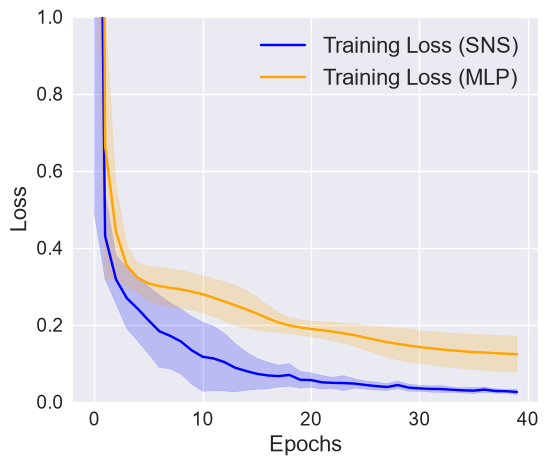

In [191]:
# Compute mean and standard deviation across runs (axis=0)
mean_curve_sns = np.mean(
    history_sns_np * (training_dataset.y_max - training_dataset.y_min).item(), axis=0
)
std_curve_sns = np.std(
    history_sns_np * (training_dataset.y_max - training_dataset.y_min).item(), axis=0
)
mean_curve_mlp = np.mean(
    history_mlp_np * (training_dataset.y_max - training_dataset.y_min).item(), axis=0
)
std_curve_mlp = np.std(
    history_mlp_np * (training_dataset.y_max - training_dataset.y_min).item(), axis=0
)


epochs = np.arange(history_sns_np.shape[1])

fig, ax = plt.subplots(figsize=(6, 5))

# Plotting
ax.plot(epochs, mean_curve_sns, label="Training Loss (SNS)", color="blue")
ax.fill_between(
    epochs,
    mean_curve_sns - std_curve_sns,
    mean_curve_sns + std_curve_sns,
    color="blue",
    alpha=0.2,
)


ax.plot(epochs, mean_curve_mlp, label="Training Loss (MLP)", color="orange")
ax.fill_between(
    epochs,
    mean_curve_mlp - std_curve_mlp,
    mean_curve_mlp + std_curve_mlp,
    color="orange",
    alpha=0.2,
)

ax.set_xlabel("Epochs", fontsize=16)
ax.set_ylabel("Loss", fontsize=16)
ax.set_ylim(0, 5e-3 * 200)
ax.legend(fontsize=16)
ax.grid(True)
ax.tick_params(axis='both', labelsize=14)

fig.savefig('training_loss.png', dpi=600, bbox_inches='tight', pad_inches=0)
fig.show()

In [200]:
a = torch.Tensor([[0, 10],[10,0]])

In [201]:
b = torch.nn.functional.gumbel_softmax(a, tau=1, hard=True)

In [202]:
b.shape

torch.Size([2, 2])

In [203]:
b[..., -1]

tensor([1., 0.])

In [199]:
b.shape

torch.Size([10, 10])

In [6]:
layer_size = [3, 3, 2, 2, 1]

In [ ]:
x = torch.Tensor([[-2, -1, 3]])

y = model(x)

In [15]:
y

tensor([[-3.5000]], grad_fn=<DivBackward0>)

In [ ]:
-2 + 1 / (-1 + 1 / 3)

-3.5

In [2]:
import torch

In [ ]:
a = torch.abs(torch.Tensor([0.001, 200]))
aa = torch.abs(a)

aa /= 1 + aa

In [10]:
aa

tensor([0.0010, 0.9950])

In [12]:
torch.Tensor([0])

tensor([0.])

In [11]:
torch.sum(aa)

tensor(0.9960)

In [ ]:
model = Network(SNS, layer_size, skip_connection=False, ac=torch.nn.Identity())

model.layers[0].w.data = torch.Tensor([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
model.layers[0].v.data = torch.Tensor([[0, 0, 0], [0, 0, 0], [0, 0, 0]])
model.layers[0].b.data = torch.Tensor([0, -1, -1])

model.layers[1].w.data = torch.Tensor([[1, 0, 0], [0, 1, 0], [0, 0, 0]])
model.layers[1].v.data = torch.Tensor([[0, 0, 0], [0, 0, 0], [0, 0, 1]])
model.layers[1].b.data = torch.Tensor([0, 0, 1])

model.layers[2].w.data = torch.Tensor([[1, 0], [0, 0], [0, 0]])
model.layers[2].v.data = torch.Tensor([[0, 0], [0, 1], [0, 1]])
model.layers[2].b.data = torch.Tensor([0, 1])

model.layers[3].w.data = torch.Tensor([[1], [1]])
model.layers[3].v.data = torch.Tensor([[0], [0]])
model.layers[3].b.data = torch.Tensor([0])

# model_learning = ManualLitModel(model, ZoAR)
# model_learning = ManualLitModel(model, ZoVanilla)

# trainer = L.Trainer(
#     max_epochs=40,
#     accelerator="auto"  # Automatically picks GPU if available, else CPU
# )

# # Run the training execution pipeline
# trainer.fit(model_learning, train_dataloaders=train_loader)

In [ ]:
data_iterator = iter(train_loader)

model.eval()
# Fetch exactly one batch of data
for i, (first_batch_features, first_batch_labels) in enumerate(data_iterator):
    if i == 0:
        print(model(first_batch_features))
        print(first_batch_labels)
        err = torch.nn.functional.mse_loss(
            model(first_batch_features), first_batch_labels
        )
        print(err)

tensor([[1.9825],
        [2.7097],
        [0.6558],
        [0.9792],
        [1.6745],
        [2.1354],
        [2.4913],
        [0.8577],
        [1.0054],
        [0.6447],
        [0.5397],
        [2.2084],
        [1.9535],
        [2.1901],
        [0.6599],
        [2.2734],
        [0.8351],
        [2.4071],
        [0.3306],
        [1.6306],
        [0.7440],
        [0.4961],
        [1.6791],
        [2.1337],
        [1.0457],
        [1.0136],
        [1.0396],
        [0.2438],
        [0.5373],
        [0.7505],
        [1.4915],
        [1.5770]], grad_fn=<DivBackward0>)
tensor([[1.9825],
        [2.7097],
        [0.6558],
        [0.9792],
        [1.6745],
        [2.1354],
        [2.4913],
        [0.8577],
        [1.0054],
        [0.6447],
        [0.5397],
        [2.2084],
        [1.9535],
        [2.1901],
        [0.6599],
        [2.2734],
        [0.8351],
        [2.4071],
        [0.2557],
        [1.6306],
        [0.7440],
        [0.4961],
   

In [ ]:
model_learning = GModel(model)

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
# trainer.fit(model_learning, train_dataloaders=train_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [28]:
trainer.test(model=model_learning, dataloaders=train_loader)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 313/313 [00:00<00:00, 455.70it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss            2177.311767578125
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_loss': 2177.311767578125}]

In [34]:
data_iterator = iter(train_loader)
first_batch_features, first_batch_labels = next(data_iterator)

In [35]:
first_batch_features

tensor([[-1.5311,  1.8800, -0.8916],
        [-1.0513,  1.8977, -1.7575],
        [ 0.2177, -1.6384,  1.6624],
        [-1.2915,  0.7900,  1.5309],
        [ 1.7858,  1.8631,  1.7042],
        [-1.2049,  0.9918, -1.5787],
        [-0.4611, -1.1526,  1.5563],
        [ 1.5064, -1.4025, -0.3540],
        [-0.9375, -1.9775,  1.2453],
        [-0.2610,  0.4306, -0.3056],
        [-0.2686,  1.7601,  0.5359],
        [-1.4303,  1.9714,  0.6998],
        [ 1.0240,  0.4833, -1.4634],
        [-0.3166, -1.9855, -0.6037],
        [ 1.6266,  0.2814,  0.1545],
        [ 0.9576, -0.5767, -0.2900],
        [-0.9958,  1.5387,  0.4881],
        [-1.8661,  0.3241,  1.1056],
        [-1.5553, -0.4927,  0.6011],
        [-0.6027,  0.1182,  0.2554],
        [-1.7650, -0.7390, -0.6644],
        [ 0.6966,  0.2366,  0.6293],
        [ 0.0622, -0.9457,  1.7567],
        [-0.0999, -1.9926, -0.0081],
        [ 1.7061,  0.1232, -1.3070],
        [-0.8799, -1.3426,  1.5136],
        [-0.5941, -0.7186,  0.0443],
 

In [36]:
first_batch_labels

tensor([[-0.2127],
        [-0.2987],
        [-0.7468],
        [-0.5986],
        [ 2.1940],
        [ 1.5855],
        [-2.4219],
        [ 1.2699],
        [-1.7890],
        [-0.6129],
        [ 0.0072],
        [-1.1362],
        [-3.9757],
        [-0.5911],
        [ 1.7746],
        [ 0.7091],
        [-0.7170],
        [-1.0522],
        [-0.7012],
        [-0.3548],
        [-2.2106],
        [ 1.2443],
        [-2.5945],
        [-0.1079],
        [ 0.1481],
        [-2.3464],
        [-0.5484],
        [ 2.9426],
        [-0.0226],
        [ 4.7602],
        [ 0.6249],
        [-0.3727]])

In [37]:
model.eval()

Network(
  (ac): Identity()
  (layers): ModuleList(
    (0-3): 4 x SNS()
  )
)

In [38]:
model(first_batch_features)

tensor([[-0.2127],
        [-0.2987],
        [-0.7468],
        [-0.5986],
        [ 2.1940],
        [ 1.5855],
        [-2.4219],
        [ 1.2699],
        [-1.7890],
        [-0.6129],
        [ 0.0072],
        [-1.1362],
        [-3.9757],
        [-0.5911],
        [ 1.7746],
        [ 0.7091],
        [-0.7170],
        [-1.0522],
        [-0.7012],
        [-0.3548],
        [-2.2106],
        [ 1.2443],
        [-2.5945],
        [-0.1833],
        [ 0.1481],
        [-2.3464],
        [-0.4864],
        [ 2.9426],
        [-0.0226],
        [ 4.7602],
        [ 0.6249],
        [-0.3727]], grad_fn=<DivBackward0>)

In [ ]:
data_iterator = iter(train_loader)

model.eval()
# Fetch exactly one batch of data
for i, (first_batch_features, first_batch_labels) in enumerate(data_iterator):
    if i == 0:
        print(model(first_batch_features))
        print(first_batch_labels)
        err = torch.nn.functional.mse_loss(
            model(first_batch_features), first_batch_labels
        )
        print(model(first_batch_features) - first_batch_labels)

        max_idx = torch.argmax(
            torch.abs(model(first_batch_features) - first_batch_labels)
        )

        print(first_batch_features[max_idx])
        print(first_batch_labels[max_idx])

        print(
            "true",
            first_batch_features[max_idx][0]
            + 1
            / (first_batch_features[max_idx][1] + 1 / first_batch_features[max_idx][2]),
        )
        print("pre", model(first_batch_features[max_idx]))

tensor([[-11.4677],
        [ -4.2776],
        [  4.4336],
        [ -0.9786],
        [ -0.5082],
        [  1.7618],
        [  0.8811],
        [ -1.9259],
        [  2.8008],
        [ -0.3790],
        [  8.1499],
        [ -9.6546],
        [  1.8058],
        [ -0.4303],
        [  1.7747],
        [ -0.8275],
        [ -0.1309],
        [  5.6306],
        [ -0.8202],
        [  0.5974],
        [ -0.3356],
        [ -0.4476],
        [  0.1391],
        [ -1.3497],
        [  7.0618],
        [ -4.7017],
        [  0.5273],
        [  8.0512],
        [  7.7589],
        [  2.3732],
        [ -1.8407],
        [ -1.2019]], grad_fn=<DivBackward0>)
tensor([[-14.7863],
        [ -4.2776],
        [  4.4336],
        [ -0.9786],
        [ -0.5082],
        [  1.7618],
        [  0.8811],
        [ -1.9259],
        [  2.8008],
        [ -0.3790],
        [  8.1499],
        [-10.9082],
        [  1.8058],
        [ -0.4303],
        [  1.7747],
        [ -0.8275],
        [ -0.13

In [ ]:
model(torch.Tensor([0.3963, -1.0364, 1.0347]))

tensor([-9.6037], grad_fn=<DivBackward0>)

In [43]:
0.3963 + 1 / (-1.0364 + 1 / 1.0347)

-13.90242802539639

In [16]:
class ManualLitModelSS(L.LightningModule):
    def __init__(self, model, zo_optimizer, tau, lambda_, alpha):
        super().__init__()
        self.model = model
        self.zo_optimizer = zo_optimizer
        self.tau = tau
        self.lambda_ = lambda_
        self.alpha = alpha
        # Turn off automatic optimization
        self.automatic_optimization = False
        self.ave_loss = torch.tensor(0.0)
        self.first_step = True

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        # Pull your custom optimizer instance
        opt = self.optimizers()

        x, y = batch

        def closure():
            y_hat = self(x)
            loss = torch.nn.functional.mse_loss(y_hat, y)
            if self.first_step:
                self.first_step = False
                self.ave_loss = loss
            else:
                self.ave_loss = 0.5 * self.ave_loss + 0.5 * loss
            return self.model.sparsity / self.lambda_ + loss - self.tau
            # return loss
            #return self.model.sparsity

        # Trigger your optimizer's custom step
        loss = opt.step(closure)

        with torch.no_grad():
            self.lambda_ *= math.exp(self.ave_loss.item() - self.tau) ** self.alpha
            self.lambda_ = min(self.lambda_, 1e4)

        # print(f"Iteration {batch_idx:02d} | Objective Value: {loss:.4f}")

        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        self.log(
            "lambda",
            torch.tensor(self.lambda_),
            on_step=True,
            on_epoch=True,
            prog_bar=True,
        )

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("val_loss", loss)
        return loss

    def test_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("test_loss", loss)

    def configure_optimizers(self):
        return self.zo_optimizer(
            [p for p in self.parameters() if p.requires_grad], lr=1e-3
        )

In [ ]:
class ManualLitModelS(L.LightningModule):
    def __init__(self, model, zo_optimizer):
        super().__init__()
        self.model = model
        self.zo_optimizer = zo_optimizer

        # Turn off automatic optimization
        self.automatic_optimization = False

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        # Pull your custom optimizer instance
        opt = self.optimizers()

        def closure():

            return self.model.sparsity

        # Trigger your optimizer's custom step
        loss = opt.step(closure)

        # print(f"Iteration {batch_idx:02d} | Objective Value: {loss:.4f}")

        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)

    # def test_step(self, batch, batch_idx):
    #     x, y = batch
    #     y_hat = self.model(x)
    #     loss = torch.nn.functional.mse_loss(y_hat, y)

    #     self.log("test_loss", loss)

    def configure_optimizers(self):
        return self.zo_optimizer(self.parameters(), lr=1e-3)

In [5]:
layer_size = [2, 10, 1]

In [61]:
model.sparsity

tensor(3.1075, grad_fn=<SumBackward1>)

In [22]:
model.sparse

True

In [ ]:
model = Network(
    Linear, layer_size, skip_connection=False, ac=torch.nn.ReLU(), sparse=False
)

In [10]:
model.layers[0].bias_strength_matrix.shape

torch.Size([10])

In [ ]:
model = Network(
    Linear, layer_size, skip_connection=False, ac=torch.nn.ReLU(), sparse=False
)
model_learning = ManualLitModel(model, ZoVanilla)


trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 82     | train | 0    
--------------------------------------------------
41        Trainable params
41        Non-trainable p

Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 172.17it/s, v_num=174, train_loss_step=0.000534, train_loss_epoch=0.00115] 

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 313/313 [00:01<00:00, 171.72it/s, v_num=174, train_loss_step=0.000534, train_loss_epoch=0.00115]


In [ ]:
# model = Network(
#     Linear, layer_size, skip_connection=False, ac=torch.nn.ReLU(), sparse=False
# )
model_learning = ManualLitModelSS(model, ZoVanilla, tau=2e-3, lambda_=1e4, alpha=1)


trainer = L.Trainer(
    max_epochs=80,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 82     | train | 0    
--------------------------------------------------
82        Trainable params
0         Non-trainable params
82        Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 33:  95%|█████████▌| 298/313 [00:04<00:00, 61.11it/s, v_num=224, train_loss_step=0.00809, lambda_step=1e+4, train_loss_epoch=0.0142, lambda_epoch=1e+4]     

In [ ]:
model = Network(
    Linear, layer_size, skip_connection=False, ac=torch.nn.ReLU(), sparse=False
)
model.sparse = True
model_learning = ManualLitModelSS(model, ZoVanilla, tau=1e-2, lambda_=1e4, alpha=1)


trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 82     | train | 0    
--------------------------------------------------
41        Trainable params
41        Non-trainable params
82        Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 39: 100%|██████████| 313/313 [00:03<00:00, 98.75it/s, v_num=172, train_loss_step=0.127, lambda_step=21.90, train_loss_epoch=0.132, lambda_epoch=21.20]          

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 313/313 [00:03<00:00, 98.61it/s, v_num=172, train_loss_step=0.127, lambda_step=21.90, train_loss_epoch=0.132, lambda_epoch=21.20]


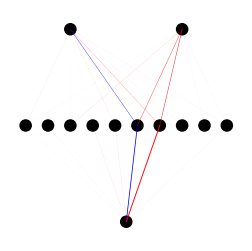

In [63]:
plot_mlp(model)

In [ ]:
a = torch.Tensor([[1, 2, 3], [-100, 1, 200]])
torch.nn.functional.gumbel_softmax(a, tau=1, hard=False, eps=1e-10, dim=-1)

tensor([[0.0027, 0.9375, 0.0598],
        [0.0000, 0.0000, 1.0000]])

In [19]:
model_learning.model.layers[0].w.device

device(type='cpu')

In [12]:
model.use_sparse_mode()

In [65]:
model.layers[1].w_gate

Parameter containing:
tensor([[0],
        [0],
        [0],
        [0],
        [0],
        [1],
        [1],
        [0],
        [0],
        [0]])

In [58]:
model.layers[1].w

Parameter containing:
tensor([[ 2.8573e-02],
        [ 2.4102e-03],
        [ 2.1767e+00],
        [-1.9450e-03],
        [ 5.0395e-02],
        [ 1.8122e-02],
        [ 3.5794e-03],
        [ 1.8809e-02],
        [-5.1983e-03],
        [-4.9330e-03]], requires_grad=True)

In [ ]:
model.use_sparse_mode()
model_learning = GModel(model)

trainer = L.Trainer(
    max_epochs=40,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(model_learning, train_dataloaders=train_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 82     | train | 0    
--------------------------------------------------
41        Trainable params
41        Non-trainable params
82        Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 39: 100%|██████████| 313/313 [00:00<00:00, 359.84it/s, v_num=185, train_loss_step=0.00158, train_loss_epoch=0.00142] 

`Trainer.fit` stopped: `max_epochs=40` reached.


Epoch 39: 100%|██████████| 313/313 [00:00<00:00, 358.07it/s, v_num=185, train_loss_step=0.00158, train_loss_epoch=0.00142]


In [ ]:
def kmeans_pytorch(X, num_clusters, max_iters=100, device="cpu"):
    # Move dataset to target device (e.g., 'cuda' or 'cpu')
    X = X.to(device)
    num_samples, num_features = X.shape

    # 1. Randomly initialize centroids from the dataset points
    random_indices = torch.randperm(num_samples)[:num_clusters]
    centroids = X[random_indices]

    for i in range(max_iters):
        # 2. Compute Euclidean distance from each point to each centroid
        # Formula: (X - centroids)^2 = X^2 - 2*X*centroids^T + centroids^2
        distances = torch.cdist(X, centroids, p=2)

        # 3. Assign points to the closest centroid
        cluster_assignments = torch.argmin(distances, dim=1)

        # 4. Update centroids by computing the mean of assigned points
        new_centroids = torch.zeros_like(centroids)
        for c in range(num_clusters):
            # Mask points matching current cluster
            assigned_points = X[cluster_assignments == c]
            if len(assigned_points) > 0:
                new_centroids[c] = assigned_points.mean(dim=0)
            else:
                # Handle empty cluster by re-initializing randomly
                new_centroids[c] = X[torch.randint(0, num_samples, (1,))]

        # Check for convergence (if centroids stop changing)
        if torch.allclose(centroids, new_centroids, atol=1e-4):
            break

        centroids = new_centroids

    return cluster_assignments, centroids


# --- Example Usage ---
# Generate 1000 random points in 2D space
data = torch.randn(1000, 2)

# Run clustering on GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
labels, centers = kmeans_pytorch(data, num_clusters=2, device=device)

In [ ]:
labels, centers = kmeans_pytorch(
    torch.abs(model.layers[0].w.data).reshape(-1, 1), num_clusters=2, device=device
)

In [42]:
labels

tensor([0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1],
       device='cuda:0')

In [44]:
model.layers[0].b.data

tensor([ 0.0008,  0.0033,  0.0062, -0.0271,  0.0273, -0.0016, -0.0043,  0.0043,
        -0.0248, -0.0187])

In [46]:
model.layers[1].w.data

tensor([[ 2.4508],
        [-0.0079],
        [ 0.0068],
        [ 0.0045],
        [ 2.4257],
        [ 0.0315],
        [-0.0029],
        [-0.0057],
        [ 0.0029],
        [ 0.0056]])

In [37]:
torch.abs(model.layers[0].w.data)

tensor([[0.2382, 0.0213, 0.0152, 0.0024, 0.2954, 0.0019, 0.0107, 0.0112, 0.0044,
         0.0121],
        [0.2919, 0.0010, 0.0114, 0.0031, 0.2920, 0.0054, 0.0243, 0.0022, 0.0207,
         0.0043]])

In [11]:
model.sparsity

tensor(8.8417, grad_fn=<SumBackward1>)

In [20]:
40 / 10000

0.004

In [49]:
layer_size = [2,100,1]

In [24]:
model = Network(
    Linear, layer_size, skip_connection=False, ac=torch.nn.SiLU(), sparse=True
)
model_learning = GModel(model, tau=1e-3, lambda_=1e4, alpha=1)


trainer = L.Trainer(
    max_epochs=100,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 82     | train | 0    
--------------------------------------------------
82        Trainable params
0         Non-trainable params
82        Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 99: 100%|██████████| 313/313 [00:01<00:00, 161.20it/s, v_num=232, train_loss_step=0.00228, lambda_step=9.91e+3, train_loss_epoch=0.00348, lambda_epoch=9.91e+3]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 313/313 [00:01<00:00, 160.73it/s, v_num=232, train_loss_step=0.00228, lambda_step=9.91e+3, train_loss_epoch=0.00348, lambda_epoch=9.91e+3]


In [11]:
class GModel(L.LightningModule):
    def __init__(self, model, tau, lambda_, alpha, lr=1e-3):
        super().__init__()
        self.model = model
        self.tau = tau
        self.lr = lr
        self.lambda_0 = lambda_
        self.lambda_ = lambda_
        self.alpha = alpha

        self.ave_loss = torch.tensor(0.0)
        self.first_step = True


    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model.forward(x)
        y_hat = y_hat.view_as(y)
        loss = torch.nn.functional.mse_loss(y_hat, y)
        if self.first_step:
            self.first_step = False
            self.ave_loss = loss
        else:
            self.ave_loss = 0.5 * self.ave_loss + 0.5 * loss
        # loss = nn.MSELoss()(y_hat.squeeze(dim=2)[:,-1], y.squeeze(dim=2)[:,-1])

        with torch.no_grad():
            self.lambda_ *= math.exp(self.ave_loss.item() - self.tau) ** self.alpha
            self.lambda_ = min(self.lambda_, self.lambda_0)


        _loss = self.model.sparsity / self.lambda_ + loss - self.tau
        #_loss = loss
        self.log("train_loss", _loss, on_step=True, on_epoch=True, prog_bar=True)
        # self.log("train_loss_epoch", loss, on_epoch=True, prog_bar=True)

        self.log(
            "lambda",
            torch.tensor(self.lambda_),
            on_step=True,
            on_epoch=True,
            prog_bar=True,
        )

        return _loss

    def test_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("test_loss", loss)

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self.model(x)
        loss = torch.nn.functional.mse_loss(y_hat, y)

        self.log("val_loss", loss)
        self.log("sparsity", self.model.sparsity)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)

In [13]:
model.layers[0].w

Parameter containing:
tensor([[-3.7475,  5.5673, -0.0160, -0.2320,  0.1364, -1.7881, -0.1067,  0.2484,
         -0.0668,  0.1842],
        [ 4.3021, -5.1550, -0.2490,  0.7047, -0.0442, -2.4959,  0.6727, -0.1778,
         -0.2062, -0.0138]], requires_grad=True)

In [38]:
model.layers[0].w_gate


Parameter containing:
tensor([[-13.3951,   6.7238, -13.8120, -12.2573, -11.4259,   1.4233, -11.9895,
         -12.5489, -12.3230,   0.9946],
        [-13.1012,   2.5735, -13.7289, -13.0277, -11.6406,   6.5101, -12.2391,
         -12.5454, -12.4237,   6.2342]], requires_grad=True)

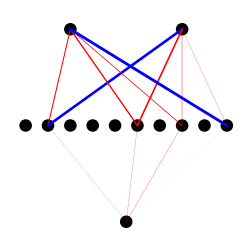

In [23]:
plot_mlp(model)

In [6]:
layer_size = [3, 10, 10, 1]

In [14]:
model = Network(
    SNS, layer_size, skip_connection=False, ac=torch.nn.Identity(), sparse=True
)

In [2]:
model.sparsity

NameError: name 'model' is not defined

In [13]:
model = Network(
    SNS, layer_size, skip_connection=False, ac=torch.nn.Identity(), sparse=True
)

In [4]:
600 / 2e6

0.0003

In [12]:
3 * 10 + 10 * 10 + 10 * 1 + 3 + 10 + 10 + 1

164

In [15]:
164 / 5e6

3.28e-05

In [22]:
# model = Network(
#     SNS, layer_size, skip_connection=False, ac=torch.nn.Identity(), sparse=True
# )

# model.use_sparse_mode()

# model.sparse = False

# model.layers[0].w.data[:,:2] = torch.Tensor([[1, 0],[0, -1]])
# model.layers[0].v.data[:,:2] = torch.Tensor([[0, 0],[0, 1000]])
# model.layers[0].b.data[:2] = torch.Tensor([0, 1])

# model.layers[1].w.data[:2,:] = torch.Tensor([[1],[0]])
# model.layers[1].v.data[:2,:] = torch.Tensor([[0],[1000]])
# model.layers[1].b.data[:1] = torch.Tensor([0])


#model_learning = GModel(model, tau=5e-4, lambda_=2e6, alpha=1)
model_learning = GModel(model, tau=2e-3, lambda_=5e5, alpha=1, lr=1e-3)


trainer = L.Trainer(
    max_epochs=1000,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
    # gradient_clip_val=0.1,
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 602    | train | 0    
--------------------------------------------------
602       Trainable params
0         Non-trainable params
602       Total params
0.002     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 999: 100%|██████████| 313/313 [00:03<00:00, 83.73it/s, v_num=378, train_loss_step=-0.0009, lambda_step=1.89e+4, train_loss_epoch=0.0015, lambda_epoch=2.21e+4]      

`Trainer.fit` stopped: `max_epochs=1000` reached.


Epoch 999: 100%|██████████| 313/313 [00:03<00:00, 83.56it/s, v_num=378, train_loss_step=-0.0009, lambda_step=1.89e+4, train_loss_epoch=0.0015, lambda_epoch=2.21e+4]


In [1]:
model

NameError: name 'model' is not defined

In [1]:
3 * 100 + 100 * 100 + 100*1 +3 + 100 + 100 + 1

10604

In [42]:
model

Network(
  (ac): Identity()
  (layers): ModuleList(
    (0-2): 3 x SNS()
  )
)

In [25]:
10604 / 5e8

2.1208e-05

In [12]:
# model = Network(
#     Linear, layer_size, skip_connection=False, ac=torch.nn.SiLU(), sparse=True
# )
# model_learning = GModel(model, tau=2e-4, lambda_=1e6, alpha=1)

model_learning = GModel(model, tau=2e-3, lambda_=5e5, alpha=1)


trainer = L.Trainer(
    max_epochs=1000,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

# Run the training execution pipeline
trainer.fit(
    model_learning, train_dataloaders=train_loader, val_dataloaders=validation_loader
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type    | Params | Mode  | FLOPs
--------------------------------------------------
0 | model | Network | 322    | train | 0    
--------------------------------------------------
322       Trainable params
0         Non-trainable params
322       Total params
0.001     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
0         Total Flops


c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Epoch 999: 100%|██████████| 313/313 [00:03<00:00, 81.15it/s, v_num=383, train_loss_step=0.000694, lambda_step=1.06e+4, train_loss_epoch=0.00119, lambda_epoch=1.21e+4]    

`Trainer.fit` stopped: `max_epochs=1000` reached.


Epoch 999: 100%|██████████| 313/313 [00:03<00:00, 80.91it/s, v_num=383, train_loss_step=0.000694, lambda_step=1.06e+4, train_loss_epoch=0.00119, lambda_epoch=1.21e+4]


In [33]:
import sympy as sp

In [ ]:
1000(1- x) / 1001(1 + 1000 * x) 

In [ ]:
1 / (1 + 1000 * x) 

In [71]:
X + 1

TypeError: unsupported operand type(s) for +: 'MutableDenseMatrix' and 'int'

In [76]:
num0.shape[1]

100

In [77]:
sp.ones(1, num0.shape[1])

Matrix([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

In [17]:
x, y = sp.symbols('x y')

# Create a 2x2 symbolic matrix
X = sp.Matrix([x, y]).T
num0 = sp.simplify(X *sp.Matrix(a0) + sp.Matrix(c0).T)
den0 = sp.simplify(X *sp.Matrix(b0) + sp.ones(1, num0.shape[1]))
activation0 = sp.Matrix(num0.shape[0], num0.shape[1], lambda i, j: num0[i, j] / den0[i, j])

num1 = sp.simplify(activation0 *sp.Matrix(a1) + sp.Matrix(c1).T)
den1 = sp.simplify(activation0 *sp.Matrix(b1) + sp.ones(1, num1.shape[1]))
activation1 = sp.Matrix(num1.shape[0], num1.shape[1], lambda i, j: num1[i, j] / den1[i, j])

In [34]:
x, y, z = sp.symbols('x y z')

# Create a 2x2 symbolic matrix
X = sp.Matrix([x, y, z]).T
num0 = sp.simplify(X *sp.Matrix(a0) + sp.Matrix(c0).T)
den0 = sp.simplify(X *sp.Matrix(b0) + sp.ones(1, num0.shape[1]))
activation0 = sp.Matrix(num0.shape[0], num0.shape[1], lambda i, j: num0[i, j] / den0[i, j])

num1 = sp.simplify(activation0 *sp.Matrix(a1) + sp.Matrix(c1).T)
den1 = sp.simplify(activation0 *sp.Matrix(b1) + sp.ones(1, num1.shape[1]))
activation1 = sp.Matrix(num1.shape[0], num1.shape[1], lambda i, j: num1[i, j] / den1[i, j])

num2 = sp.simplify(activation1 *sp.Matrix(a2) + sp.Matrix(c2).T)
den2 = sp.simplify(activation1 *sp.Matrix(b2) + sp.ones(1, num2.shape[1]))
activation2 = sp.Matrix(num2.shape[0], num2.shape[1], lambda i, j: num2[i, j] / den2[i, j])

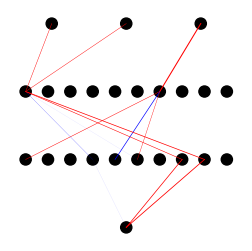

In [36]:
plot_sns(model)

In [35]:
activation0

Matrix([[(0.622952*x + 0.622874*y - 0.451813)/(0.853144*z + 1), 0.225669, 0.00802497, -0.708265, 0.0234868, -0.00925715, 2.20703*z - 1.09107, 0.269032, 0.0122068, -0.114953]])

In [37]:
activation1

Matrix([[1.48424*z - 0.893217, 0.0150803, 0.0184906, (-0.156092*x - 0.156073*y + 0.306424*z + 0.47238)/(0.853144*z + 1), (1.42024 - 2.11712*z)/(0.905247*z + 0.552481), (-0.0353629*x - 0.0353585*y + 1.02016*z**2 + 0.691793*z - 0.565076)/(0.853144*z + 1.0), -0.0319924, (0.485749*x + 0.485688*y + 0.648486*z + 0.40781)/((0.550679*z + 0.727765)*(0.853144*z + 1)), (0.626024*x + 0.625946*y - 0.463531*z - 0.997362)/(0.853144*z + 1), -0.00904982]])

In [38]:
activation2

Matrix([[(0.362836*z**4 + 1.55154*z**3 + 2.43439*z**2 + 1.6491*z + 0.402076)*(0.404825*x*z + 1.04422*x + 0.404774*y*z + 1.04409*y - 0.0715166*z**2 + 0.207852*z - 0.0713078)/((0.469808*z**2 + 1.17157*z + 0.727765)*(-0.00480877*x*z**3 - 0.00646261*x*z**2 + 0.000318715*x*z + 0.00150853*x - 0.00480817*y*z**3 - 0.0064618*y*z**2 + 0.000318674*y*z + 0.00150834*y + 0.316352*z**5 + 1.25042*z**4 + 2.07086*z**3 + 2.15005*z**2 + 1.57696*z + 0.568995))]])

In [96]:
sp.denom(activation2[0]).subs({x: 1, y: 2, z: 5})

38291.2

In [31]:
activation0[-31]

0.897536*x - 0.558092

In [36]:
activation0[-4]

(0.891571 - 2.37046*y)/(20.5564*y + 1)

In [40]:
a1

array([[ 0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [ 0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [ 0.       ],
       [-0.       ],
       [-0.       ],
       [-0.       ],
       [ 0.       ],
       [ 0.  

In [41]:
b1

array([[-0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [-0.      ],
       [ 0.      ],
       [-0.      ],
       [-0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [ 0.      ],
       [-0.      ],
       [ 0.      ],
       [ 0.      ],


In [47]:
c1

array([0.23274593], dtype=float32)

In [28]:
c0[]

np.float32(-0.5580922)

In [21]:
num, denom = activation1[0].as_numer_denom()

In [22]:
num

(5.30336*x + 1)*(5.38663*y + 1)*(-2.35144*x*(4.29849*x + 1) - 1.41489*y*(2.39232*y + 1) + (2.32759*x + 1.38807*y)*(4.29849*x + 1)*(2.39232*y + 1))

In [26]:
sp.expand(num)

683.772*x**3*y**2 + 124.01*x**3*y - 0.543696*x**3 + 407.769*x**2*y**3 + 534.153*x**2*y**2 + 83.8759*x**2*y - 0.229005*x**2 + 75.0555*x*y**3 + 75.3018*x*y**2 + 11.2642*x*y - 0.0238502*x - 0.345681*y**3 - 0.20867*y**2 - 0.026825*y

In [25]:
sp.expand(denom)

293.768*x**2*y**2 + 502.946*x**2*y + 158.904*x**2 + 432.826*x*y**2 + 398.423*x*y + 90.9159*x + 84.7934*y**2 + 65.469*y + 12.5506

In [81]:
activation0

Matrix([[0, 0, 0, 0, -2.81056*y/(10.9732*y + 1), 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -0.484112*x, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [31]:
activation1[0].subs({x: 1000, y: 1000})

3706.34

In [64]:
c

Matrix([[0, 0, 0, 0, -2.81056*y, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -0.484112*x, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [11]:
a0 = model.layers[0].w * (torch.sigmoid(model.layers[0].w_gate) > 0.5)
a0 = a0.detach().cpu().numpy()

b0 = model.layers[0].v * (torch.sigmoid(model.layers[0].v_gate) > 0.5)
b0 = b0.detach().cpu().numpy()

c0 = model.layers[0].b * (torch.sigmoid(model.layers[0].b_gate) > 0.5)
c0 = c0.detach().cpu().numpy()

a1 = model.layers[1].w * (torch.sigmoid(model.layers[1].w_gate) > 0.5)
a1 = a1.detach().cpu().numpy()

b1 = model.layers[1].v * (torch.sigmoid(model.layers[1].v_gate) > 0.5)
b1 = b1.detach().cpu().numpy()

c1 = model.layers[1].b * (torch.sigmoid(model.layers[1].b_gate) > 0.5)
c1 = c1.detach().cpu().numpy()

In [31]:
a0 = model.layers[0].w * (torch.sigmoid(model.layers[0].w_gate) > 0.5)
a0 = a0.detach().cpu().numpy()

b0 = model.layers[0].v * (torch.sigmoid(model.layers[0].v_gate) > 0.5)
b0 = b0.detach().cpu().numpy()

c0 = model.layers[0].b
c0 = c0.detach().cpu().numpy()

a1 = model.layers[1].w * (torch.sigmoid(model.layers[1].w_gate) > 0.5)
a1 = a1.detach().cpu().numpy()

b1 = model.layers[1].v * (torch.sigmoid(model.layers[1].v_gate) > 0.5)
b1 = b1.detach().cpu().numpy()

c1 = model.layers[1].b
c1 = c1.detach().cpu().numpy()

In [32]:
a2 = model.layers[2].w * (torch.sigmoid(model.layers[2].w_gate) > 0.5)
a2 = a2.detach().cpu().numpy()

b2 = model.layers[2].v * (torch.sigmoid(model.layers[2].v_gate) > 0.5)
b2 = b2.detach().cpu().numpy()

c2 = model.layers[2].b
c2 = c2.detach().cpu().numpy()

In [23]:
model.layers[0].v * torch.sigmoid(model.layers[0].v_gate)

tensor([[-6.3200e-09, -1.2502e+00,  1.5989e-07,  6.5475e-12,  1.6572e-07,
         -6.3812e-09, -1.4615e-09,  1.0388e-07, -8.2049e-08, -9.9081e-09],
        [-3.7372e-09,  6.8254e+00,  1.4307e-07, -7.3250e-09,  4.3001e-08,
         -8.9517e-09, -8.3090e-09,  1.0703e-07,  4.6204e-08,  1.3039e-09]],
       grad_fn=<MulBackward0>)

In [19]:
model.layers[0].b * torch.sigmoid(model.layers[0].b_gate)

tensor([-4.6630e-08,  1.1095e-07,  1.9882e-08,  6.4267e-08, -4.8594e-08,
        -6.1388e-09,  3.0672e-09, -2.9639e-09, -3.4779e-08, -3.2906e-08],
       grad_fn=<MulBackward0>)

In [33]:
ww0 = model.layers[0].w * torch.sigmoid(model.layers[0].w_gate)
vv0 = model.layers[0].v * torch.sigmoid(model.layers[0].v_gate)
bb0 = model.layers[0].b * torch.sigmoid(model.layers[0].b_gate)


ww1 = model.layers[1].w * torch.sigmoid(model.layers[1].w_gate)
vv1 = model.layers[1].v * torch.sigmoid(model.layers[1].v_gate)
bb1 = model.layers[1].b * torch.sigmoid(model.layers[1].b_gate)

In [28]:
ww0[0, 4]

tensor(-1.5627, grad_fn=<SelectBackward0>)

In [34]:
ww1[4]

tensor([-2.9205e-10], grad_fn=<SelectBackward0>)

In [32]:
bb0

tensor([-2.4354e-08,  4.8556e-09, -1.6164e-08, -1.0277e-08,  1.2961e-07,
         4.6589e-09, -8.6445e-09,  7.3674e-08, -2.0694e-09, -1.5403e-09,
         4.3039e-09,  1.2156e-08,  4.8573e-08,  9.3525e-09,  1.2847e-08,
        -2.0551e-09,  1.2835e-08,  6.7733e-09,  7.5792e-09,  1.4391e-08,
         1.1462e-08, -1.5010e-08,  1.7570e-08, -5.0276e-08,  4.1413e-09,
         1.0101e-08, -5.2814e-09,  1.3396e-10,  1.2185e-08,  2.7631e-08,
         2.5264e-08,  1.7254e-08,  3.3886e-08, -3.3558e-08,  3.8518e-09,
        -2.5344e-08,  1.5444e-08, -1.0817e-08, -1.8233e-09, -4.1661e-09,
         2.2792e-08, -9.8242e-10,  2.9554e-09, -8.4910e-09, -1.8179e-08,
         3.1715e-08, -6.4258e-09, -6.2925e-10, -1.8153e-08, -3.9198e-09,
        -2.2217e-08,  1.0399e-08,  2.8438e-09, -8.5453e-09,  1.1862e-08,
        -1.6269e-08, -2.2091e-08, -6.3138e-08,  1.3851e-08,  3.1649e-08,
        -6.4174e-09,  2.1986e-08, -5.0448e-09,  8.4540e-09, -1.0854e-08,
         6.7468e-09,  2.3856e-09, -1.1841e-09,  1.5

In [27]:
vv0[0, 4]

tensor(8.1174, grad_fn=<SelectBackward0>)

In [35]:
vv1[4]

tensor([6.3880], grad_fn=<SelectBackward0>)

In [ ]:
(x1-1.5627)/(1 + 8.1174 * x1)

In [ ]:
/(1 + 6.3880 (x1-1.5627)/(1 + 8.1174 * x1))

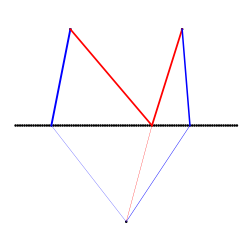

In [12]:
plot_mlp(model)

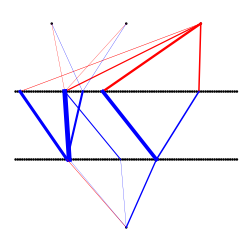

In [7]:
plot_mlp(model)

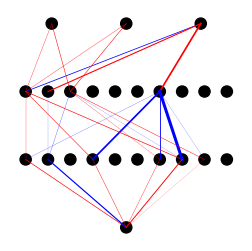

In [41]:
plot_mlp(model)

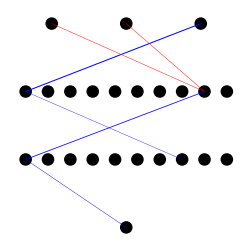

In [17]:
plot_sns(model)

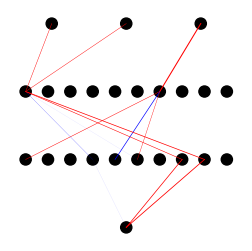

In [30]:
plot_sns(model)

In [10]:
torch.sigmoid(model.layers[0].w_gate) > 0.5

tensor([[False, False, False, False,  True, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False,  True, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False],
        [False, False, False, False, False, False, False,  True, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, 

In [22]:
model.layers[1].w[4]

tensor([-0.0026], grad_fn=<SelectBackward0>)

In [21]:
model.layers[1].v[4]

tensor([6.3929], grad_fn=<SelectBackward0>)

In [19]:
torch.sigmoid(model.layers[1].v_gate) > 0.5

tensor([[False],
        [False],
        [False],
        [False],
        [ True],
        [False],
        [False],
        [ True],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False

In [18]:
torch.sigmoid(model.layers[1].w_gate) > 0.5

tensor([[False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [ True],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [ True],
        [False

In [17]:
model.layers[0].w[0, 23]

tensor(0.7133, grad_fn=<SelectBackward0>)

In [16]:
model.layers[0].v_gate[0, 23]

tensor(6.7352, grad_fn=<SelectBackward0>)

In [11]:
torch.sigmoid(model.layers[0].v_gate) > 0.5

tensor([[False, False, False, False,  True, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False,  True, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False],
        [False, False, False, False, False, False, False,  True, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, 

In [87]:
model = Network(
    SNS, layer_size, skip_connection=False, ac=torch.nn.Identity(), sparse=False
)
model.layers[0].w.data = torch.zeros_like(model.layers[0].w.data)
model.layers[0].v.data = torch.zeros_like(model.layers[0].v.data)
model.layers[0].b.data = torch.zeros_like(model.layers[0].b.data)
model.layers[1].w.data = torch.zeros_like(model.layers[1].w.data)
model.layers[1].v.data = torch.zeros_like(model.layers[1].v.data)
model.layers[1].b.data = torch.zeros_like(model.layers[1].b.data)

model.layers[0].w.data[:,:2] = torch.Tensor([[1, 0],[0, -1]])
model.layers[0].v.data[:,:2] = torch.Tensor([[0, 0],[0, 1000]])
model.layers[0].b.data[:2] = torch.Tensor([0, 1])

model.layers[1].w.data[:2,:] = torch.Tensor([[1],[0]])
model.layers[1].v.data[:2,:] = torch.Tensor([[0],[1000]])
model.layers[1].b.data[:1] = torch.Tensor([0])


model_learning = GModel(model, tau=5e-4, lambda_=2e4, alpha=1)


trainer = L.Trainer(
    max_epochs=300,
    accelerator="auto",  # Automatically picks GPU if available, else CPU
)

trainer.test(model_learning, dataloaders=train_loader)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling 

Testing DataLoader 0: 100%|██████████| 313/313 [00:00<00:00, 594.27it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss          7.324332727876026e-06
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_loss': 7.324332727876026e-06}]

In [40]:
training_dataset.x_max

tensor([0.9999, 0.9999])

In [ ]:
c

In [45]:
first_labels

tensor([[0.1836],
        [0.0412],
        [0.0052],
        [0.3467],
        [0.0044],
        [0.1148],
        [0.2418],
        [0.0073],
        [0.0718],
        [0.5464],
        [0.1003],
        [0.2727],
        [0.1707],
        [0.5364],
        [0.4986],
        [0.0132],
        [0.2270],
        [0.0018],
        [0.0641],
        [0.0602],
        [0.3477],
        [0.4380],
        [0.2527],
        [0.0269],
        [0.1521],
        [0.0922],
        [0.4250],
        [0.5710],
        [0.0529],
        [0.3481],
        [0.2741],
        [0.2029]])

In [48]:
model.layers[0].b

Parameter containing:
tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

In [44]:
model_learning(first_inputs)

tensor([[13.3884],
        [12.0654],
        [14.3138],
        [13.7435],
        [10.1438],
        [18.5483],
        [13.0013],
        [10.3848],
        [13.6205],
        [15.5983],
        [13.9191],
        [13.0782],
        [12.3089],
        [16.5219],
        [18.7512],
        [12.3166],
        [15.0983],
        [10.1538],
        [10.9670],
        [14.0106],
        [15.6977],
        [16.2576],
        [14.6843],
        [17.1304],
        [17.4266],
        [18.1653],
        [14.7350],
        [16.8119],
        [12.2052],
        [16.6184],
        [13.0329],
        [16.1619]], grad_fn=<DivBackward0>)

In [41]:
training_dataset.x_min

tensor([3.5468e-04, 1.5644e-05])

In [8]:
# model = Network(
#     SNS, layer_size, skip_connection=False, ac=torch.nn.Identity(), sparse=True
# )

model.set_sparse_mode(
    sparse=True
)

model_learning = GModel0(model)

In [10]:
model.layers

ModuleList(
  (0-2): 3 x SNS()
)

In [9]:
for layer in model.layers:
    layer.w_gate.data = 10 * torch.ones_like(layer.w_gate.data)
    # layer.v_gate.data = 10 * torch.ones_like(layer.v_gate.data)
    layer.b_gate.data = 10 * torch.ones_like(layer.b_gate.data)

In [10]:
trainer.test(model=model_learning, dataloaders=train_loader)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
c:\Users\Yanjun\Documents\sns_lib\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 313/313 [00:00<00:00, 338.12it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss         0.00016878843598533422
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_loss': 0.00016878843598533422}]

In [31]:
c = model.layers[1].w.data[:,:2]

In [32]:
c.shape

torch.Size([10, 1])

In [26]:
model.layers[0].b.data[:2]

tensor([0., 0.])

In [24]:
model.layers[0].w.data

tensor([[ 1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]])

In [9]:
model.eval()
pred = model(training_dataset.data["features"])


In [23]:
model.ac

Identity()

In [37]:
activation0

Matrix([[0, 0, 0, 0, 2.14254*x/(22.6326*x + 1), 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.930412*y, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [24]:
first_inputs, first_labels = next(iter(train_loader))

history = []
x = first_inputs
with torch.no_grad():
    for idx, layer in enumerate(model.layers):
        x = layer(x)
        if idx < model.depth - 1:
            x = model.ac(x)
        history.append(x)

In [28]:
model.sparse

True

In [42]:
model.layers[0].w_gate

Parameter containing:
tensor([[-17.4517, -17.4525, -17.4497, -17.4515,   7.3822, -17.4526, -17.4474,
         -17.4527, -17.4510, -17.4506, -17.4499, -17.4126, -17.4501, -17.4477,
         -17.4461, -17.4501, -17.4488, -17.4444, -17.4511, -17.4420, -17.2047,
         -17.4505, -17.4511, -17.3824, -17.4503, -17.4485, -17.2875, -17.4062,
         -17.4509, -17.4462, -17.4507, -17.4478, -17.4514, -17.4480, -17.4520,
         -17.4511, -17.4515, -17.4499, -17.4460, -17.4485, -17.4478, -17.4468,
         -17.4436, -17.4415, -17.4538, -17.4501, -17.4502, -17.4522, -17.4438,
         -17.4453, -17.4372, -17.4506, -17.4140, -17.4473, -17.4430, -17.4454,
         -17.4480, -17.4533, -17.4513, -17.4501, -17.4483, -17.4528, -17.4525,
         -17.4340, -17.4492, -17.4488, -17.4530, -17.4520, -17.4509, -17.4483,
         -17.4507, -17.4457, -17.4308, -17.4493, -17.4033, -17.4465, -17.4449,
         -17.4223, -17.3959, -17.4318, -17.3224, -17.4518, -17.4486, -17.4527,
         -17.0036, -17.4457, -

In [43]:
w_gate, v_gate, b_gate = model.layers[0].gate

In [48]:

x = first_inputs

w = model.layers[0].w
v = model.layers[0].v
b = model.layers[0].b


if model.sparse:
    w_gate, v_gate, b_gate = model.layers[0].gate
    w = w * w_gate
    v = v * v_gate
    if model.layers[0].bias_on:
        b = b * b_gate

num = torch.matmul(x, w)
if model.layers[0].bias_on:
    num += b
if model.layers[0].skip_connection:
    num += x
den = torch.matmul(x, v) + 1

an = torch.div(num, den)

In [49]:
an

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], grad_fn=<DivBackward0>)

Text(0.5, 0, 'Z Label')

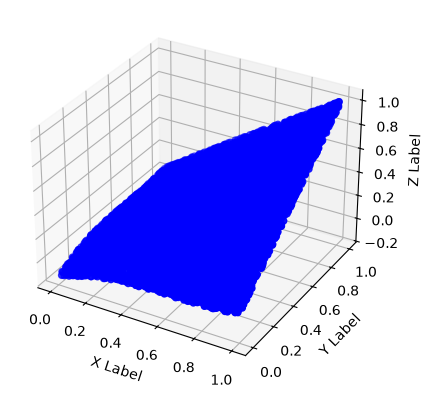

In [10]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

# Plot the 3D scatter data

ax.scatter(
    training_dataset.data["features"][:, 0],
    training_dataset.data["features"][:, 1],
    pred.data[:, 0],
    c="blue",
    marker="o",
)

# ax.scatter(training_dataset.data["features"][:, 0], training_dataset.data["features"][:, 1], training_dataset.data["features"][:, 2], c=training_dataset.data["labels"][:,0], cmap='viridis', s=40, edgecolors='w', linewidth=0.5)

# Add axis labels
ax.set_xlabel("X Label")
ax.set_ylabel("Y Label")
ax.set_zlabel("Z Label")

# ax.view_init(elev=30, azim=45, roll=0)

Text(0.5, 0, 'Z Label')

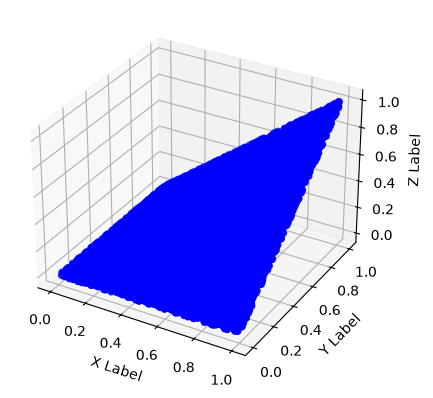

In [11]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

# Plot the 3D scatter data

ax.scatter(
    training_dataset.data["features"][:, 0],
    training_dataset.data["features"][:, 1],
    training_dataset.data["labels"][:, 0],
    c="blue",
    marker="o",
)

# ax.scatter(training_dataset.data["features"][:, 0], training_dataset.data["features"][:, 1], training_dataset.data["features"][:, 2], c=training_dataset.data["labels"][:,0], cmap='viridis', s=40, edgecolors='w', linewidth=0.5)

# Add axis labels
ax.set_xlabel("X Label")
ax.set_ylabel("Y Label")
ax.set_zlabel("Z Label")

# ax.view_init(elev=30, azim=45, roll=0)

In [43]:
import numpy as np

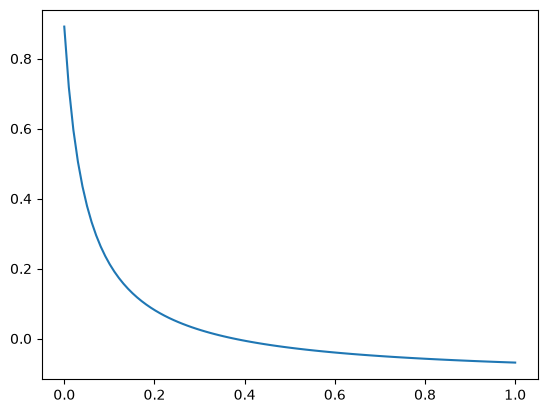

In [45]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot()

# Plot the 3D scatter data

x1 = np.linspace(0, 1, 100)
y1 = (0.891571 - 2.37046*x1) / (20.5564*x1 + 1)

ax.plot(x1, y1)

In [34]:
syn_data = torch.zeros_like(training_dataset.data["features"])
syn_data.data = training_dataset.data["features"].data
syn_data[:, -1] = 5
model.eval()
pred = model(syn_data)

In [39]:
syn_data = torch.Tensor(training_dataset.data["features"])
syn_data[:, -2] = 10
model.eval()
pred = model(syn_data)

In [38]:
training_dataset = RegressionDataset(
    RationalInteraction(), num_samples=10000, low=[0, 0, 0], high=[10, 10, 20], noise_level=0.0, normalize=False
)
validation_dataset = RegressionDataset(
    RationalInteraction(), num_samples=3000, low=[0, 0, 0], high=[10, 10, 20], noise_level=0.0, normalize=False
)

# training_dataset = RegressionDataset(NestedRational(), num_samples=10000, low = [0, 0, 0], high = [2.0, 2.0, 2.0], noise_level=0)

train_loader = DataLoader(training_dataset, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=32, shuffle=False)

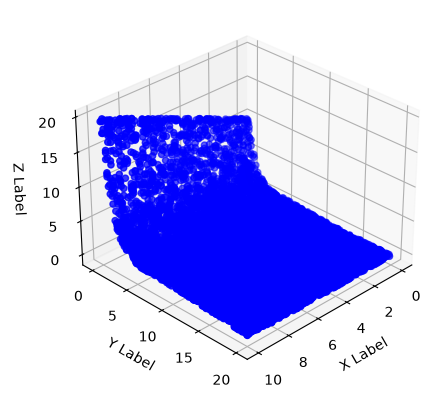

In [40]:
import matplotlib.pyplot as plt

# Create a figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

# Plot the 3D scatter data

ax.scatter(
    training_dataset.data["features"][:, 0],
    training_dataset.data["features"][:, 2],
    pred.data[:, 0],
    c="blue",
    marker="o",
)

# ax.scatter(training_dataset.data["features"][:, 0], training_dataset.data["features"][:, 1], training_dataset.data["features"][:, 2], c=training_dataset.data["labels"][:,0], cmap='viridis', s=40, edgecolors='w', linewidth=0.5)

# Add axis labels
ax.set_xlabel("X Label")
ax.set_ylabel("Y Label")
ax.set_zlabel("Z Label")

ax.view_init(elev=30, azim=45, roll=0)

In [39]:
torch.max(training_dataset.data["features"][:, 0])

tensor(1.)